## UIDB

This approach will calculate true depth of SfM point cloud using refractive index directly 

### Getting started

To ensure working environment works properly, set to the top level of repository

In [1]:
cd ..

d:\PROGRAM\PYTHON\sfm-bathy-mapper


### Load Packages

Firstly, we need to import packages that will be use in this notebook

In [2]:
import pandas as pd
import numpy as np
import os


import sfmbathy.bathy_ml as bm

### Set Input and Output Directory

Set input and output folder (Please be aware with folder name)

In [7]:
train_txt =r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_KEP_SERIBU\PANGGANG_USV_MSL_TRAINING.csv"
image_tif = r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_KEP_SERIBU\ORTHO_PANGGANG_15CM.tif"
val_txt = r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_KEP_SERIBU\PANGGANG_USV_MSL_6M.csv"
folder_output = r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_KEP_SERIBU\OUTPUT_XGB_USV_TRAIN_6"
os.makedirs(folder_output, exist_ok=True)

[1] Training points read      : 3735
[2] Valid points after sampling: 3735
    Split (spatial) : train 2680 (72 %) | test 1055 (28 %)
[3] Fitted XGBOOST
    Training   : RMSE=0.117  MAE=0.081  R2=0.995  Bias=-0.000  N=2680
    CV         : RMSE=0.419  MAE=0.244  R2=0.936  Bias=-0.018  N=2680
    Hold-out test : RMSE=0.466  MAE=0.268  R2=0.887  Bias=0.094  N=1055


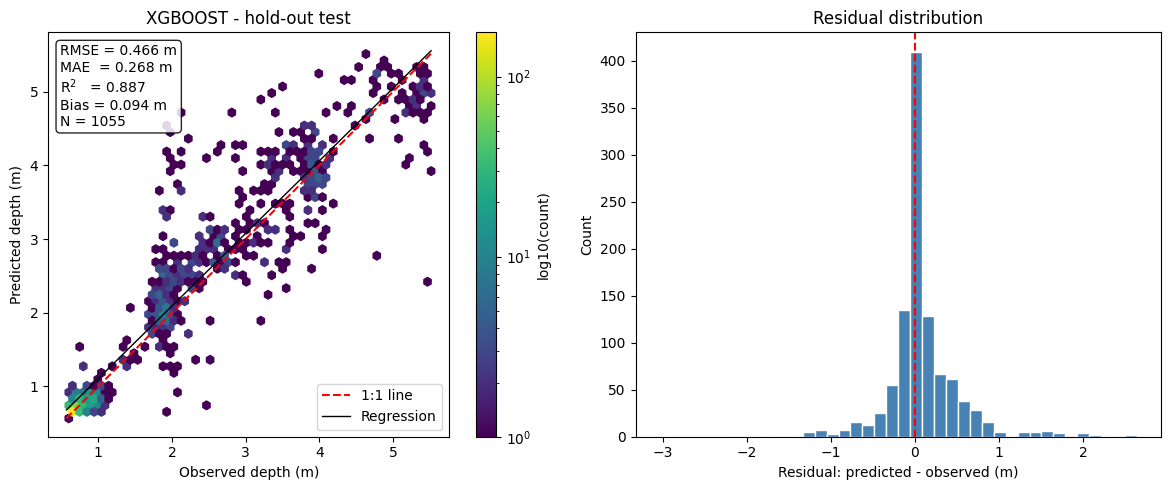

[4] External validation points : 4425 of 4425 (inside image, valid pixels)
    Validation : RMSE=0.261  MAE=0.134  R2=0.971  Bias=0.028  N=4425


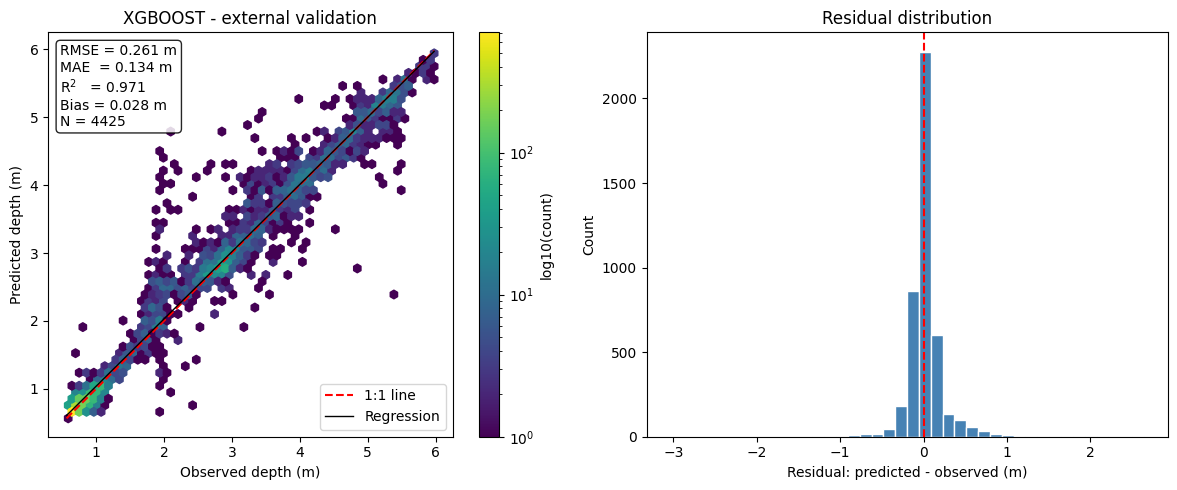

    DEM prediction: 10% (83/828 tiles)
    DEM prediction: 20% (166/828 tiles)
    DEM prediction: 30% (249/828 tiles)
    DEM prediction: 40% (332/828 tiles)
    DEM prediction: 50% (414/828 tiles)
    DEM prediction: 60% (497/828 tiles)
    DEM prediction: 70% (580/828 tiles)
    DEM prediction: 80% (663/828 tiles)
    DEM prediction: 90% (746/828 tiles)
    DEM prediction: 100% (828/828 tiles)
[5] DEM written                : D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_KEP_SERIBU\OUTPUT_XGB_USV_TRAIN_6\xgb_usv_panggang.tif
    Model saved                : D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_KEP_SERIBU\OUTPUT_XGB_USV_TRAIN_6\xgb_usv_panggang.joblib
    Statistics saved           : D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_KEP_SERIBU\OUTPUT_XGB_USV_TRAIN_6\xgb_usv_panggang_metrics.csv, D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_KEP_SERIBU\OUTPUT_XGB_USV_TRAIN_6\xgb_usv_panggang_settings.json, D:\OneDriv

In [8]:
res = bm.run_bathymetry(
    train_txt=train_txt,
    image_tif=image_tif,
    val_txt=val_txt,
    model="xgb",
    test_size=0.25,                    # 75 % training / 25 % testing
    split_method="spatial",            # "spatial" (recommended) or "random"
    # block_size=50,                     # block size (map units) for the spatial split
    refit_full=False,                  # True = refit on 100 % of points before DEM
    z_is_depth=False,
    max_depth=6,
    output_as_elevation=True,
    # feature_scale_m=0.25,
    aggregate="median", 
    # thin_cell=1.0,
    n_jobs=-1,
        save_model_path=os.path.join(folder_output, "xgb_usv_panggang.joblib"),  # fitted model (joblib)
    plot_path=os.path.join(folder_output, "xgb_usv_panggang.png"),     # figure (PNG)
    stats_prefix=os.path.join(folder_output, "xgb_usv_panggang"),     # statistics (CSV / JSON / Excel
    output_dem=os.path.join(folder_output, "xgb_usv_panggang.tif"),  # DEM (GeoTIFF)       
)

print(res["train_metrics"])   # fitted on the 75 %
print(res["test_metrics"])    # hold-out 25 %
print(res["val_metrics"])     # external validation (USV)

## PREDICT OTHER LOCATION

Predict in Pramuka and Kelapa Dua Island

In [3]:
model =r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_KEP_SERIBU\OUTPUT_XGB_USV_TRAIN_8\xgb_usv_panggang.joblib"
image_other = r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_PRAMUKA\ORTHO_PRAMUKA_15CM.tif"
output_dem = r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_PRAMUKA\DEM_PRAMUKA_XGB_USV_TRAIN_6.tif"
val_usv = r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_PRAMUKA\PRAMUKA_USV_ELLIPSOID.csv"


Model: xgboost (trained 2026-11-09T17:00:31), clip range: 0.591 - 7.999 m
       feature scale: None m, aggregate: median, z_is_depth: False, z_offset: 0.0
NOTE: RGB-based models transfer best to the same camera, similar water clarity, bottom type and lighting. A different water level shifts the result: set z_offset.
External check: 2210 of 2210 points inside the image with valid pixels
    Result: RMSE=0.260  MAE=0.206  R2=-3.207  Bias=0.171  N=2210
    Mean bias +0.171 m. z_offset = +0.171 would remove it, but that calibrates on these points, so they would no longer be an independent check.


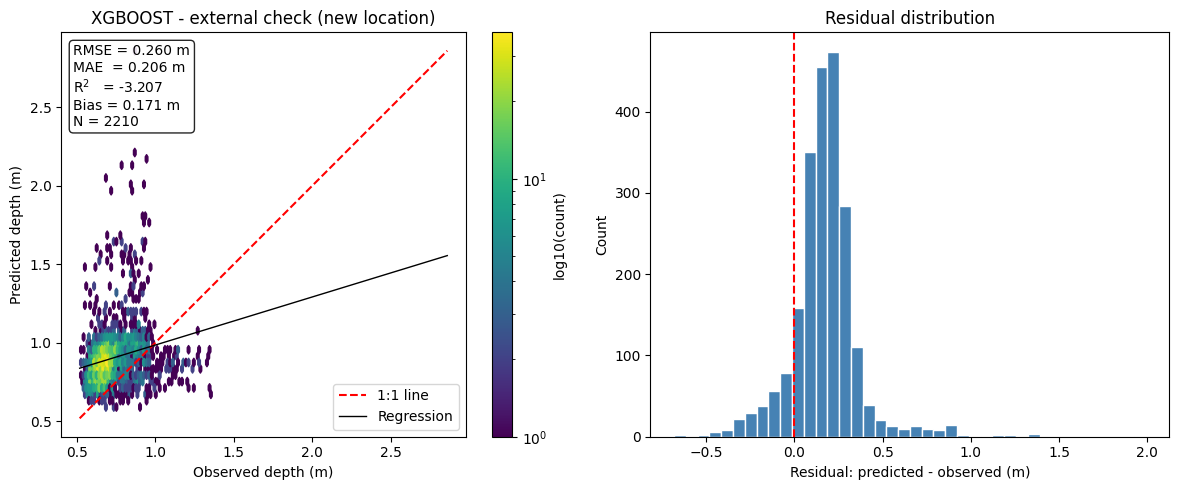

    DEM prediction: 10% (53/528 tiles)
    DEM prediction: 20% (106/528 tiles)
    DEM prediction: 30% (159/528 tiles)
    DEM prediction: 40% (212/528 tiles)
    DEM prediction: 50% (264/528 tiles)
    DEM prediction: 60% (317/528 tiles)
    DEM prediction: 70% (370/528 tiles)
    DEM prediction: 80% (423/528 tiles)
    DEM prediction: 90% (476/528 tiles)
    DEM prediction: 100% (528/528 tiles)
DEM written: D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\ML_PRAMUKA\DEM_PRAMUKA_XGB_USV_TRAIN_6.tif
Statistics saved: out/check_B_metrics.csv, out/check_B_settings.json, out/check_B_validation_points.csv, out/check_B_results.xlsx
{'RMSE': 0.2601880374295115, 'MAE': 0.2063456273128544, 'R2': -3.2071991618075675, 'Bias': 0.17124439846595485, 'N': 2210}
0.17124439846595485


In [4]:
out = bm.apply_model(
    model_path=model,
    image_tif=image_other,
    output_tif=output_dem,        # None = only run the check
    val_txt=val_usv,               # independent check data (x, y, z)
    output_as_elevation=True,          # DEM negative
    plot_path="out/check_B.png",
    stats_prefix="out/check_B",
)
print(out["val_metrics"])              # RMSE, MAE, R2, Bias, N
print(out["suggested_z_offset"])       # offset that would remove the mean bias

## Set Parameter for Tide Modelling

Predicting tide height for determining current water level based on INATIDES model.

In [5]:
tide_dir=r"D:\tide_models" # Directory where the tide model files are stored
model="INATIDES" # Tide model to use for predictions (e.g., "INATIDES", "TPXO", "FES", etc.)
x = lon_med # Longitude of the location for tide predictions
y = lat_med # Latitude of the location for tide predictions
start_time = "2021-08-29 03:22:00" # In UTC time, Start time for tide predictions (in the format "YYYY-MM-DD HH:MM:SS") 
end_time = "2021-08-29 03:56:00" # In UTC time, End time for tide predictions (in the format "YYYY-MM-DD HH:MM:SS") 
freq = "10min" # Frequency of tide predictions (e.g., '1H' for hourly) and '10min' for every 10 minutes

# Refractive index of water
n_water = "default" # You can specify a custom value for the refractive index of water, or use "default" to use the standard value (approximately 1.33)


In [6]:
tide_results, wl = tide_calc(tide_dir, model, x, y, start_time, end_time, freq) 

Modelling tides with INATIDES
Location Lon: 106.566552, Lat: -5.648954 | time range: 2021-08-29 03:22:00 to 2021-08-29 03:56:00
Representative Water Level: 0.162 m , refer to MSL
Representative Water Level: 19.086 m , refer to Ellipsoid Reference


<Axes: xlabel='time'>

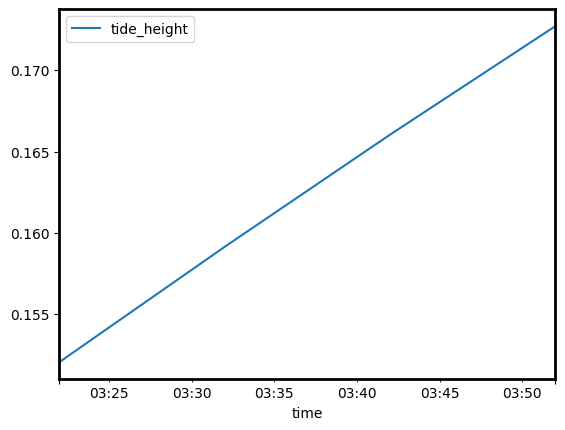

In [8]:
tide_results.droplevel(["x", "y"]).plot(legend=True)

### First Corrected Point Cloud Using Small Angle Method

The initial point clound will be corrected by small angle method using refractive index.

In [15]:
pc_sa = process_small_angle(pc, wl, n_water="default")

Number of points below water level: 4433883, percentage: 99.91%
Number of points above water level: 3938, percentage: 0.09%
Original point cloud size: 4437821, Corrected point cloud size: 4437821


In [7]:
input_train = r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\KELAPA_DUA\KELAPADUA_PC_SA_USV_TRAIN.las"
pc_train,las,lon_med,lat_med = load_las(input_train)
mean_elev= np.mean(pc_train[:,2])
print(f"Mean elevation : {mean_elev:.3f} meters (Elevation relative to WGS84 ellipsoid)")   

CRS EPSG:32748 → EPSG:4326 | Median Lon: 106.566391, Lat: -5.649013
Mean elevation : 17.729 meters (Elevation relative to WGS84 ellipsoid)


### Running depth correction based on SVM Approach

This process will correct point cloud using machine learning with Support Vector Regression (SVR). The training data would be in situ data such as echo sounder survey or bathymetric LiDAR.



In [8]:
result = svm_depth_prediction(
        sfm_points=pc,
        usv_points=pc_train,
        wl=wl,
        max_match_dist=2.0,
        test_size=0.8,
        grid_search=True,
        n_jobs=-1,
        verbose=True,
    )

[svm_depth_prediction] 4433883 underwater points (Z <= 19.0861759185791) used for SVR; 3938 land points (Z > 19.0861759185791) passed through unchanged.
[svm_depth_prediction] Matched 45539 USV points to underwater SfM points (mean match distance = 0.004).
[svm_depth_prediction] Best params from grid search: {'C': 100, 'epsilon': 0.01, 'gamma': 0.1}
[svm_depth_prediction] Test metrics -> RMSE: 0.1542, MAE: 0.0071, R2: 0.9329


In [8]:
report = result["svm_model"]
report

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",1
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",100
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [9]:
pc_corrected = np.array(result["point_cloud_predicted"])
pc_corrected

array([[6.72977120e+05, 9.37538652e+06, 1.43376646e+01, 1.80000000e+01,
        8.90000000e+01, 1.02000000e+02],
       [6.72977540e+05, 9.37538708e+06, 1.44721054e+01, 2.40000000e+01,
        1.04000000e+02, 1.19000000e+02],
       [6.72976610e+05, 9.37538663e+06, 1.41217852e+01, 2.20000000e+01,
        1.05000000e+02, 1.18000000e+02],
       ...,
       [6.73789080e+05, 9.37527060e+06, 1.91200000e+01, 1.62000000e+02,
        1.51000000e+02, 1.52000000e+02],
       [6.73790080e+05, 9.37527212e+06, 1.96200000e+01, 2.30000000e+01,
        3.50000000e+01, 4.50000000e+01],
       [6.73789080e+05, 9.37527193e+06, 1.94500000e+01, 1.04000000e+02,
        1.09000000e+02, 1.09000000e+02]], shape=(4437821, 6))

In [19]:
result_iter = svm_depth_prediction(
        sfm_points=pc_corrected,
        usv_points=train,
        wl=wl,
        max_match_dist=2.0,
        test_size=0.7,
        grid_search=True,
        n_jobs=-1,
        verbose=True,
    )

[svm_depth_prediction] 4433883 underwater points (Z <= 19.0861759185791) used for SVR; 3938 land points (Z > 19.0861759185791) passed through unchanged.
[svm_depth_prediction] Matched 1163 USV points to underwater SfM points (mean match distance = 0.159).
[svm_depth_prediction] Best params from grid search: {'C': 100, 'epsilon': 0.05, 'gamma': 'auto'}
[svm_depth_prediction] Test metrics -> RMSE: 0.0877, MAE: 0.0583, R2: 0.8907


In [20]:
pc_corrected_iter = np.array(result_iter["point_cloud_predicted"])
pc_corrected_iter

array([[6.72977120e+05, 9.37538652e+06, 1.74899197e+01, 1.80000000e+01,
        8.90000000e+01, 1.02000000e+02],
       [6.72977540e+05, 9.37538708e+06, 1.74899197e+01, 2.40000000e+01,
        1.04000000e+02, 1.19000000e+02],
       [6.72976610e+05, 9.37538663e+06, 1.74899197e+01, 2.20000000e+01,
        1.05000000e+02, 1.18000000e+02],
       ...,
       [6.73789080e+05, 9.37527060e+06, 1.91200000e+01, 1.62000000e+02,
        1.51000000e+02, 1.52000000e+02],
       [6.73790080e+05, 9.37527212e+06, 1.96200000e+01, 2.30000000e+01,
        3.50000000e+01, 4.50000000e+01],
       [6.73789080e+05, 9.37527193e+06, 1.94500000e+01, 1.04000000e+02,
        1.09000000e+02, 1.09000000e+02]], shape=(4437821, 6))

### Validation Workflow

Set validation parameter :
1. Validation data
2. Tide datum model
3. Point cloud and validation data coordinate system (EPSG)
4. Depth range for validation
5. Output directory


In [13]:
valid_dir = train # Validation file (ASCII: X, Y, Z columns) for bathymetry comparison
datum_model = r"D:\tide_models\DATUM\IS_MSL_ELLIPSOID.tif" # tide datum model (GeoTIFF) for converting ellipsoid heights to MSL heights
pc_epsg = 32748  # EPSG code for the point cloud coordinate system 
min_depth = 0  # Filter: minimum depth (m, positive downward)
max_depth = 10# Filter: maximum depth (m). None = no limit
output_validation = r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\KELAPA_DUA\HASIL_UJI_SA"   # Directory to save outputs


SfM BATHYMETRY VALIDATION WORKFLOW

[1/7] Loading data...
Loaded point cloud array: 4437821 points
Loaded validation data: CHECK_POINT_USV.txt | 1163 points

[2/7] Transforming to EPSG:4326...

[3/7] Reading datum offsets...
Read datum offsets: 4437821/4437821 points within GeoTIFF bounds
Read datum offsets: 1163/1163 points within GeoTIFF bounds

[4/7] Converting ellipsoid → MSL...
Converted to MSL: 4437821/4437821 points valid
Converted to MSL: 1163/1163 points valid

[5/7] Spatial matching (nearest neighbor)...
Spatial matching: 1163/1163 validation points matched (threshold: 10 m)

[6/7] Filtering by depth range...
Depth range filter (0-10 m): 1163/1163 points retained

[7/7] Calculating metrics and generating plots...

Metrics (1163 points):
  MAE:  0.1148 m
  RMSE: 0.1433 m
  MBE:  0.0990 m
  R²:   0.7287
  Pearson r: 0.9304 (p=0.00e+00)

Generating visualizations...
Saved scatter plot: D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\KELAPA_DUA\HASIL_UJI_SA\scatter_re

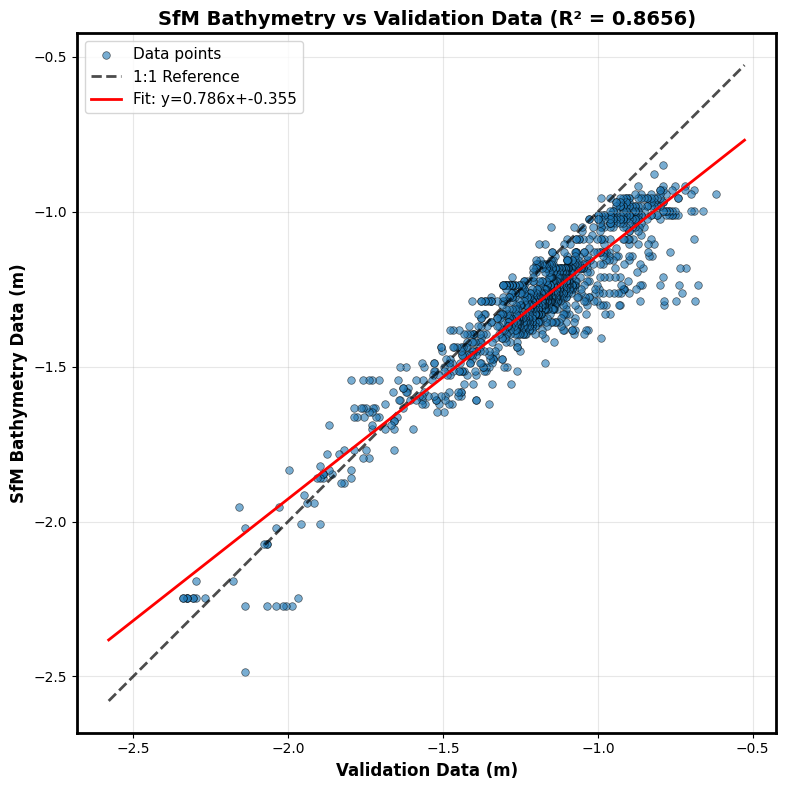

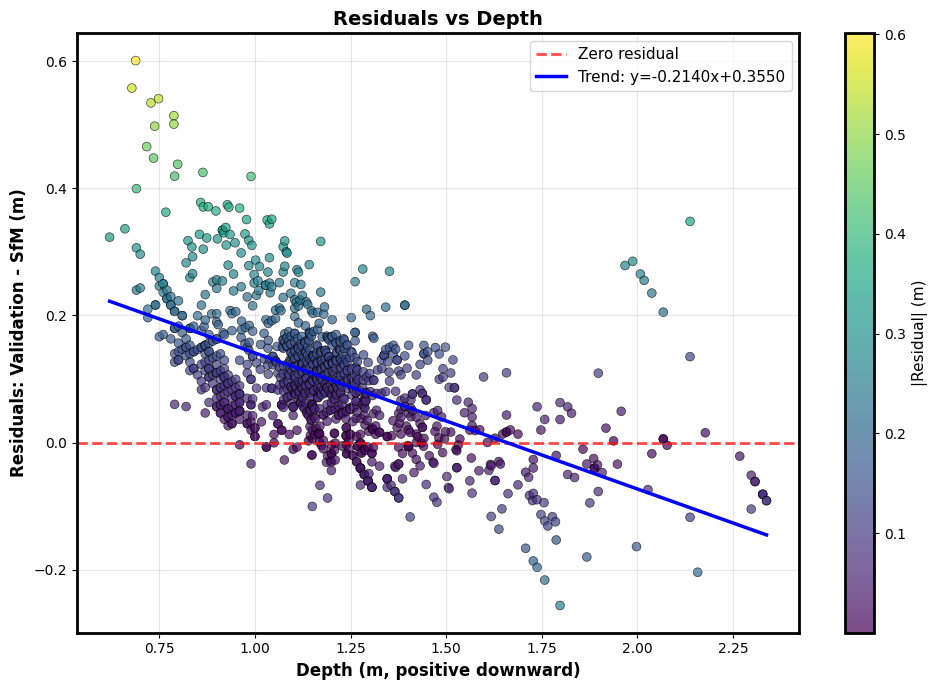

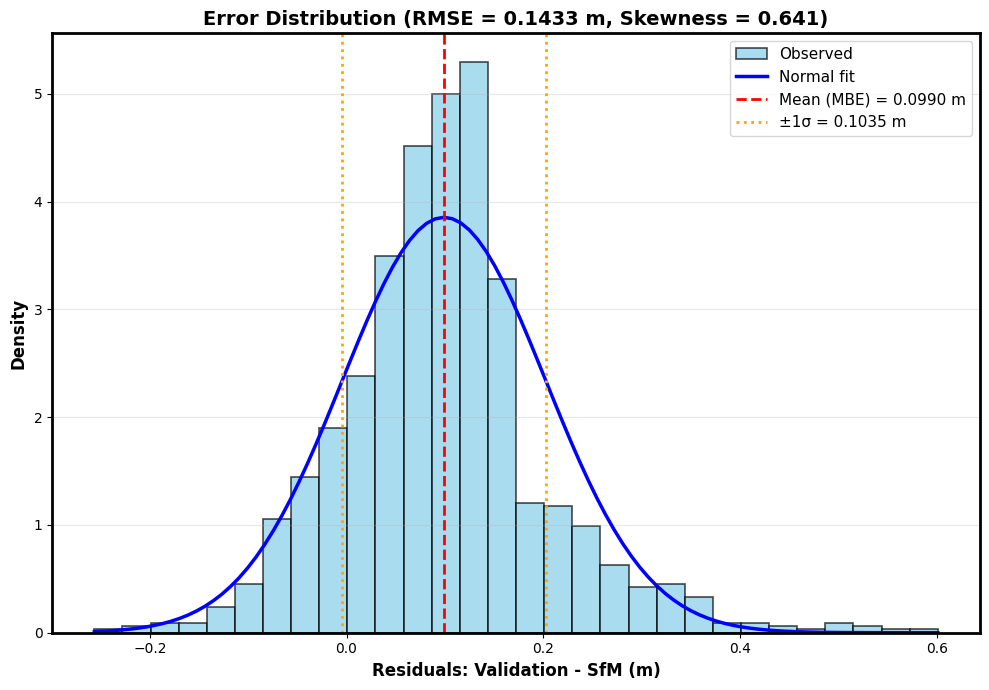

In [16]:
results = validate_bathymetry(
    pc_source= pc_sa, validation_file= valid_dir, datum_geotiff=datum_model, pc_epsg = pc_epsg,
    min_depth= min_depth, max_depth=max_depth,                                  
    max_match_distance=10, msl_reference=0, output_dir=output_validation      
)

Export Point Cloud

In [ ]:
export_pc(pc_sa, las, output) 

Corrected LAS file saved to: D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\KELAPA_DUA\KELAPADUA_PC_SA_output.las


In [10]:
output1 = r"D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\KELAPA_DUA\KELAPADUA_PC_SVM_USV.las"

export_pc(pc_corrected, las, output1)

Corrected LAS file saved to: D:\OneDrive\COMPUTER\S2-MASTER\DATA_TESIS\KEPULAUAN_SERIBU\KELAPA_DUA\KELAPADUA_PC_SVM_USV.las
